# Introducción al Análisis de Varianza (ANOVA)
## Del modelo paramétrico a la generalización: qué podemos concluir y bajo qué condiciones

**Curso:** Regresión y modelos lineales · **Bases:** `Cars93` (datos reales) y experimentos simulados

---

### Competencia que se trabaja

> *Muestra disposición para el estudio de generalizaciones acordes con la rigidez impuesta por la estructura paramétrica que se considere.*

¿Qué significa esto en la práctica? Cada vez que usamos un ANOVA **suponemos una estructura**: que la respuesta se forma como *media general + efecto del grupo + error normal con la misma varianza en todos los grupos*. Esa estructura es **rígida**: nos da herramientas potentes (la prueba $F$, intervalos, comparaciones), pero **sólo** autoriza a generalizar si los datos son compatibles con ella. A lo largo del cuadernillo vamos a:

- **escribir** la estructura paramétrica con precisión,
- **ver** qué conclusiones permite (y cuáles no),
- **comprobar** con simulación qué pasa cuando la estructura no se cumple, y
- **flexibilizarla** cuando haga falta (Welch, transformaciones, no paramétricos, más factores, covariables).

### Ruta de la clase

| Unidad | Tema | Pregunta guía |
|---|---|---|
| 1 | Fundamentos de ANOVA | ¿Por qué comparar medias analizando **varianzas**? |
| 2 | Estructura del modelo ANOVA | ¿Qué supone exactamente el modelo y qué parámetros se pueden estimar? |
| 3 | Análisis de varianza | ¿Cómo se descompone la variabilidad total? |
| 4 | Pruebas de hipótesis | ¿Cómo decidimos, y qué hacemos si los supuestos fallan? |
| 5 | Extensiones | Dos factores, bloques, covariables, efectos aleatorios |

> 💡 Ejecute las celdas en orden con `Shift + Enter`. Las celdas marcadas con ✏️ invitan a modificar valores y observar qué cambia.

---
## Preparación del entorno

In [1]:
# Si falta alguna librería, quite el '#' y ejecute una vez:
# %pip install pandas numpy matplotlib seaborn statsmodels scipy

In [2]:
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import FTestAnovaPower

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)

def ruta_datos(nombre):
    for carpeta in [Path("../datos"), Path("datos"), Path(".")]:
        if (carpeta / nombre).exists():
            return carpeta / nombre
    raise FileNotFoundError(f"No encuentro {nombre}. Colóquelo en la carpeta 'datos' del repositorio.")

print("Entorno listo ✔")

Entorno listo ✔


---
# UNIDAD 1. Fundamentos de ANOVA

## 1.1 La pregunta del ANOVA

> **¿La media de una variable respuesta cuantitativa es la misma en varios grupos, o al menos uno difiere?**

Ejemplos:
- ¿El rendimiento de un proceso depende de la temperatura de operación (baja, media, alta)?
- ¿El tiempo de atención difiere entre 4 sedes de una EPS?
- ¿El precio de un automóvil depende de su tipo (pequeño, compacto, mediano, grande, deportivo, van)?

Usaremos este último caso con datos reales: **`Cars93`**, 93 modelos de automóviles vendidos en EE. UU. en 1993.

In [3]:
cars = pd.read_csv(ruta_datos("Cars93.csv"), index_col=0)
cars.columns = [c.replace(".", "_") for c in cars.columns]          # nombres compatibles con fórmulas
orden_tipos = ["Small", "Compact", "Midsize", "Large", "Sporty", "Van"]
cars["Type"] = pd.Categorical(cars["Type"], categories=orden_tipos)
cars[["Manufacturer", "Model", "Type", "Origin", "DriveTrain", "Horsepower", "Price"]].head(8)

,Manufacturer,Model,Type,Origin,DriveTrain,Horsepower,Price
1,Acura,Integra,Small,non-USA,Front,140,15.9
2,Acura,Legend,Midsize,non-USA,Front,200,33.9
3,Audi,90,Compact,non-USA,Front,172,29.1
4,Audi,100,Midsize,non-USA,Front,172,37.7
5,BMW,535i,Midsize,non-USA,Rear,208,30.0
6,Buick,Century,Midsize,USA,Front,110,15.7
7,Buick,LeSabre,Large,USA,Front,170,20.8
8,Buick,Roadmaster,Large,USA,Rear,180,23.7


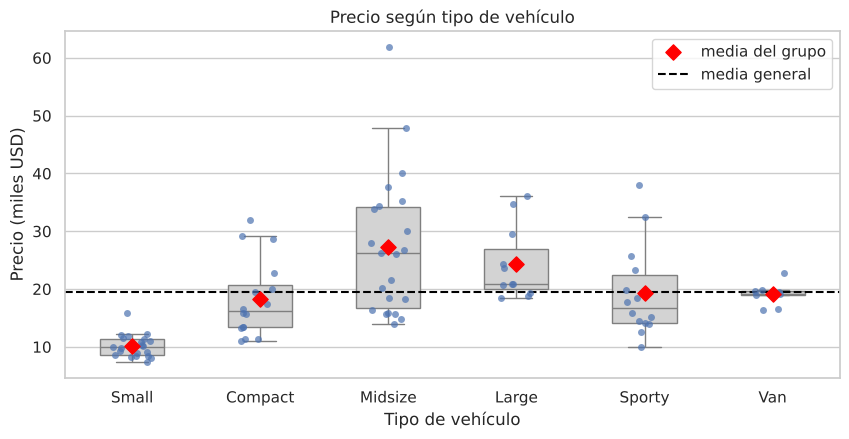

,n,media,desviación
Type,,,
Small,21,10.17,1.95
Compact,16,18.21,6.69
Midsize,22,27.22,12.26
Large,11,24.30,6.34
Sporty,14,19.39,7.97
Van,9,19.10,1.88


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=cars, x="Type", y="Price", color="lightgray", width=.5, ax=ax, showfliers=False)
sns.stripplot(data=cars, x="Type", y="Price", ax=ax, alpha=.7, jitter=.15)
medias = cars.groupby("Type", observed=True).Price.mean()
ax.scatter(range(len(medias)), medias, color="red", marker="D", s=60, zorder=5, label="media del grupo")
ax.axhline(cars.Price.mean(), ls="--", color="black", label="media general")
ax.set(xlabel="Tipo de vehículo", ylabel="Precio (miles USD)", title="Precio según tipo de vehículo")
ax.legend(); plt.show()

cars.groupby("Type", observed=True).Price.agg(n="count", media="mean", desviación="std").round(2)

Las medias muestrales son distintas… pero **siempre** lo serán, aunque sea por azar. La pregunta estadística es si las diferencias son **más grandes de lo que el azar produciría**.

## 1.2 Vocabulario básico

| Término | Significado | En el ejemplo |
|---|---|---|
| **Variable respuesta** | Variable cuantitativa que medimos | `Price` |
| **Factor** | Variable categórica que define los grupos | `Type` |
| **Niveles** | Categorías del factor ($k$) | 6 tipos |
| **Tratamiento** | Nivel (o combinación de niveles) aplicado a una unidad | "Midsize" |
| **Unidad experimental** | Lo que recibe el tratamiento y se mide | Cada modelo de auto |
| **Réplicas** ($n_i$) | Observaciones por nivel | 21 pequeños, 16 compactos… |
| **Diseño balanceado** | Todos los $n_i$ iguales | Aquí **no** es balanceado |
| **Efecto fijo** | Los niveles son *los* de interés | Los 6 tipos |
| **Efecto aleatorio** | Los niveles son una muestra de una población de niveles | 5 operarios elegidos al azar (Unidad 5) |

> 🔬 **Experimento vs. estudio observacional.** Si el investigador **asigna al azar** los tratamientos (experimento), el ANOVA permite hablar de **efectos causales**. En `Cars93` el tipo no se asignó al azar: sólo hablamos de **diferencias asociadas** al tipo. La técnica es la misma; lo que cambia es el **alcance de la generalización**.

## 1.3 ¿Por qué no hacer muchas pruebas $t$?

Con $k=6$ grupos hay $\binom{6}{2}=15$ pares. Si hacemos 15 pruebas $t$ con $\alpha=0.05$, la probabilidad de **al menos un falso positivo** (si en realidad todas las medias son iguales) es aproximadamente

$$
\alpha_{familia} = 1-(1-\alpha)^m = 1-0.95^{15} \approx 0.54.
$$

¡Más de la mitad de las veces "encontraríamos" una diferencia inexistente! Comprobémoslo por simulación:

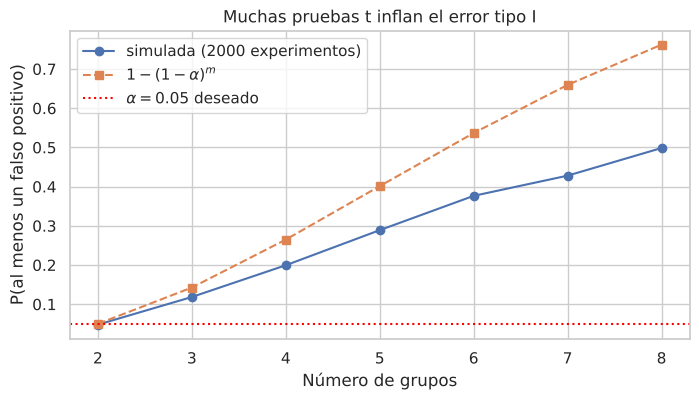

,k_grupos,pares_m,teórica_(independencia),simulada
0,2,1,0.050,0.048
1,3,3,0.143,0.118
2,4,6,0.265,0.200
3,5,10,0.401,0.289
4,6,15,0.537,0.376
5,7,21,0.659,0.428
6,8,28,0.762,0.498


In [5]:
def tasa_error_familia(k, n=15, reps=2000, alfa=0.05, rng=rng):
    falsos = 0
    for _ in range(reps):
        grupos = [rng.normal(50, 10, n) for _ in range(k)]        # H0 VERDADERA: todas las medias = 50
        pvals = [stats.ttest_ind(a, b).pvalue for a, b in combinations(grupos, 2)]
        falsos += min(pvals) < alfa                               # ¿al menos un "hallazgo"?
    return falsos / reps

tabla = pd.DataFrame({"k_grupos": range(2, 9)})
tabla["pares_m"] = tabla.k_grupos * (tabla.k_grupos - 1) // 2
tabla["teórica_(independencia)"] = 1 - 0.95 ** tabla.pares_m
tabla["simulada"] = [tasa_error_familia(k) for k in tabla.k_grupos]

plt.figure(figsize=(8, 4))
plt.plot(tabla.k_grupos, tabla.simulada, "o-", label="simulada (2000 experimentos)")
plt.plot(tabla.k_grupos, tabla["teórica_(independencia)"], "s--", label=r"$1-(1-\alpha)^m$")
plt.axhline(0.05, color="red", ls=":", label=r"$\alpha=0.05$ deseado")
plt.xlabel("Número de grupos"); plt.ylabel("P(al menos un falso positivo)")
plt.title("Muchas pruebas t inflan el error tipo I"); plt.legend(); plt.show()
tabla.round(3)

La simulación queda algo por debajo de la fórmula porque las 15 pruebas no son independientes (comparten grupos), pero el mensaje es claro: **el error se dispara**. El ANOVA resuelve esto con **una sola prueba global** de nivel $\alpha$.

## 1.4 La idea central: comparar dos fuentes de variabilidad

¿Por qué se llama análisis de **varianza** si queremos comparar **medias**? Porque la evidencia de que las medias difieren está en comparar:

- **Variabilidad ENTRE grupos:** qué tan separadas están las medias de los grupos.
- **Variabilidad DENTRO de los grupos:** qué tanto varían las observaciones alrededor de su propia media (el "ruido").

Observe los dos escenarios siguientes. **Las medias de los grupos son exactamente las mismas** en ambos; sólo cambia el ruido.

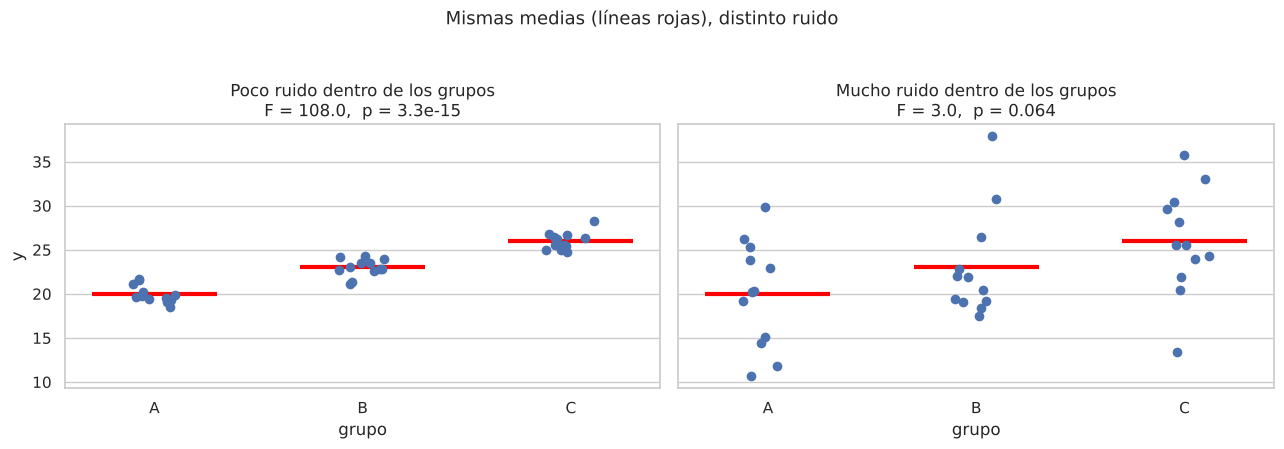

In [6]:
medias_verdaderas = [20, 23, 26]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, sd, titulo in zip(axes, [1.0, 6.0], ["Poco ruido dentro de los grupos", "Mucho ruido dentro de los grupos"]):
    datos = []
    for g, mu in zip("ABC", medias_verdaderas):
        x = rng.normal(0, 1, 12); x = (x - x.mean()) / x.std(ddof=1) * sd + mu   # medias y DE exactas
        datos.append(pd.DataFrame({"grupo": g, "y": x}))
    datos = pd.concat(datos)
    sns.stripplot(data=datos, x="grupo", y="y", ax=ax, size=7, jitter=.12)
    for i, mu in enumerate(medias_verdaderas):
        ax.hlines(mu, i - .3, i + .3, color="red", lw=3)
    F, p = stats.f_oneway(*[d.y for _, d in datos.groupby("grupo")])
    ax.set_title(f"{titulo}\nF = {F:.1f},  p = {p:.2g}")
plt.suptitle("Mismas medias (líneas rojas), distinto ruido", y=1.04, fontsize=13)
plt.tight_layout(); plt.show()

- A la **izquierda**, las diferencias entre medias son grandes **comparadas con el ruido** → evidencia clara de que los grupos difieren.
- A la **derecha**, las mismas diferencias se "pierden" en el ruido → no podemos afirmar que difieran.

Esa razón es el **estadístico $F$**:

$$
F=\frac{\text{variabilidad entre grupos}}{\text{variabilidad dentro de los grupos}}.
$$

Si $H_0$ es cierta, $F\approx 1$; si las medias difieren, $F$ crece.

> 🧭 **Idea para recordar:** el ANOVA no pregunta "¿son distintas las medias?", sino "¿son **más distintas de lo que el ruido explicaría**?".

---
# UNIDAD 2. Estructura del modelo ANOVA

## 2.1 Dos maneras equivalentes de escribir el modelo (un factor)

Sea $y_{ij}$ la observación $j$ del grupo $i$, con $i=1,\dots,k$ y $j=1,\dots,n_i$; $N=\sum n_i$.

**Modelo de medias de celda**

$$y_{ij}=\mu_i+\varepsilon_{ij}$$

**Modelo de efectos**

$$y_{ij}=\mu+\tau_i+\varepsilon_{ij}$$

| Símbolo | Nombre | Interpretación |
|---|---|---|
| $\mu$ | media general | nivel de referencia común |
| $\tau_i=\mu_i-\mu$ | efecto del tratamiento $i$ | cuánto se desplaza el grupo $i$ respecto a $\mu$ |
| $\varepsilon_{ij}$ | error aleatorio | lo que el modelo no explica |

## 2.2 Los supuestos: la "rigidez" de la estructura paramétrica

$$\varepsilon_{ij}\overset{iid}{\sim}N(0,\sigma^2)$$

Esta línea contiene **cuatro** supuestos:

| Supuesto | Qué afirma | Qué pasa si falla |
|---|---|---|
| **Independencia** | Las observaciones no se influyen entre sí | El más grave: invalida errores estándar y $p$-valores |
| **Media cero** | Los grupos difieren *sólo* en $\mu_i$ | Si hay otra fuente sistemática (p. ej. una covariable), se confunde |
| **Homocedasticidad** | **El mismo** $\sigma^2$ en todos los grupos | La prueba $F$ puede volverse liberal o conservadora (lo veremos en la Unidad 4) |
| **Normalidad** | Errores con distribución normal | Con $n$ moderado la prueba $F$ es bastante robusta |

> 🔒 **¿Por qué "rígida"?** El modelo afirma que **todo** lo que distingue a un grupo de otro es un desplazamiento de la media. La forma de la distribución y la dispersión son **idénticas** en todos los grupos. Si en la realidad un grupo es mucho más disperso o asimétrico, el modelo no tiene un parámetro para representarlo… y nuestras generalizaciones heredan ese error.

## 2.3 Un problema de estructura: los parámetros no son identificables

El modelo de efectos tiene $k+1$ parámetros ($\mu,\tau_1,\dots,\tau_k$), pero los datos sólo informan sobre $k$ medias. Hay **infinitas** combinaciones que producen las mismas medias:

$$\mu=20,\ \tau=(-3,0,3)\quad\text{y}\quad\mu=25,\ \tau=(-8,-5,-2)\quad\Rightarrow\quad\mu_i=(17,20,23)\text{ en ambos casos.}$$

En términos matriciales $\mathbf{y}=\mathbf{X}\boldsymbol\beta+\boldsymbol\varepsilon$, la matriz de diseño **no tiene rango completo**. Veámoslo con un ejemplo pequeño (3 grupos, 2 observaciones cada uno):

In [7]:
grupo = np.repeat(["A", "B", "C"], 2)
X_sobre = pd.DataFrame({"mu": 1,
                        "tau_A": (grupo == "A").astype(int),
                        "tau_B": (grupo == "B").astype(int),
                        "tau_C": (grupo == "C").astype(int)}, index=grupo)
print("Matriz de diseño del modelo de efectos SIN restricciones:")
display(X_sobre)
print(f"Columnas: {X_sobre.shape[1]}   |   Rango: {np.linalg.matrix_rank(X_sobre)}")
print("La columna 'mu' es la suma de las otras tres -> X'X no es invertible.")

Matriz de diseño del modelo de efectos SIN restricciones:


,mu,tau_A,tau_B,tau_C
A,1,1,0,0
A,1,1,0,0
B,1,0,1,0
B,1,0,1,0
C,1,0,0,1
C,1,0,0,1


Columnas: 4   |   Rango: 3
La columna 'mu' es la suma de las otras tres -> X'X no es invertible.


### La solución: imponer una restricción

Para que los parámetros sean únicos se agrega **una** restricción. Las dos más usadas:

| Restricción | Parametrización | Significado de los coeficientes | En `statsmodels` |
|---|---|---|---|
| **Celda de referencia** $\tau_1=0$ | `Treatment` (por defecto) | Intercepto = media del grupo de referencia; cada coeficiente = diferencia con la referencia | `C(Type)` |
| **Suma cero** $\sum_i\tau_i=0$ | `Sum` (efectos) | Intercepto = promedio de las medias de grupo; cada coeficiente = desviación de ese promedio | `C(Type, Sum)` |

> 💡 Esto es **exactamente** lo que se hace en regresión con variables *dummy*: un ANOVA **es** una regresión lineal con predictores categóricos.

Ajustemos el modelo con ambas restricciones sobre `Cars93` (usaremos $\log(\text{Price})$; en la Unidad 4 justificamos por qué).

In [8]:
cars["logPrice"] = np.log(cars.Price)

m_ref = smf.ols("logPrice ~ C(Type)", data=cars).fit()          # restricción: tau_Small = 0
m_sum = smf.ols("logPrice ~ C(Type, Sum)", data=cars).fit()     # restricción: suma de tau = 0

print("Parametrización de REFERENCIA (Small = 0):")
print(m_ref.params.round(4).to_string())
print("\nParametrización de SUMA CERO:")
print(m_sum.params.round(4).to_string())

Parametrización de REFERENCIA (Small = 0):
Intercept             2.3029
C(Type)[T.Compact]    0.5414
C(Type)[T.Midsize]    0.9139
C(Type)[T.Large]      0.8597
C(Type)[T.Sporty]     0.5936
C(Type)[T.Van]        0.6425

Parametrización de SUMA CERO:
Intercept                  2.8947
C(Type, Sum)[S.Small]     -0.5919
C(Type, Sum)[S.Compact]   -0.0504
C(Type, Sum)[S.Midsize]    0.3220
C(Type, Sum)[S.Large]      0.2679
C(Type, Sum)[S.Sporty]     0.0018


In [9]:
# ...pero las cantidades que importan son IDÉNTICAS
comparacion = pd.DataFrame({
    "media_muestral": cars.groupby("Type", observed=True).logPrice.mean(),
    "predicha_ref": m_ref.predict(pd.DataFrame({"Type": orden_tipos})).values,
    "predicha_sum": m_sum.predict(pd.DataFrame({"Type": orden_tipos})).values,
})
display(comparacion.round(4))
print(f"SCRes referencia = {m_ref.ssr:.6f}   |   SCRes suma cero = {m_sum.ssr:.6f}")
print(f"F global referencia = {m_ref.fvalue:.4f}   |   F global suma cero = {m_sum.fvalue:.4f}")

,media_muestral,predicha_ref,predicha_sum
Type,,,
Small,2.3029,2.3029,2.3029
Compact,2.8443,2.8443,2.8443
Midsize,3.2168,3.2168,3.2168
Large,3.1626,3.1626,3.1626
Sporty,2.8965,2.8965,2.8965
Van,2.9454,2.9454,2.9454


SCRes referencia = 8.608482   |   SCRes suma cero = 8.608482
F global referencia = 21.0444   |   F global suma cero = 21.0444


### Conclusión clave: ¿qué es *estimable*?

- Los **coeficientes individuales** dependen de la restricción elegida → **no** tienen significado por sí solos.
- Las **medias de grupo** $\mu_i$, las **diferencias** $\mu_i-\mu_j$ y en general los **contrastes** $\sum c_i\mu_i$ con $\sum c_i=0$ son **iguales** bajo cualquier restricción → son **funciones estimables**.

> 🔒 **Generalizar con rigor** significa reportar las cantidades estimables (medias, diferencias, contrastes), no un "efecto $\tau_i$" cuyo valor depende de una convención.

## 2.4 La estructura paramétrica en acción: simulación

Si **conocemos** el modelo verdadero, podemos ver cómo se comportan los estimadores. Simulamos un proceso con $\mu=20$, efectos $\tau=(-3,0,3)$, $\sigma=2$ y $n=8$ por grupo, y repetimos el "experimento" 2000 veces.

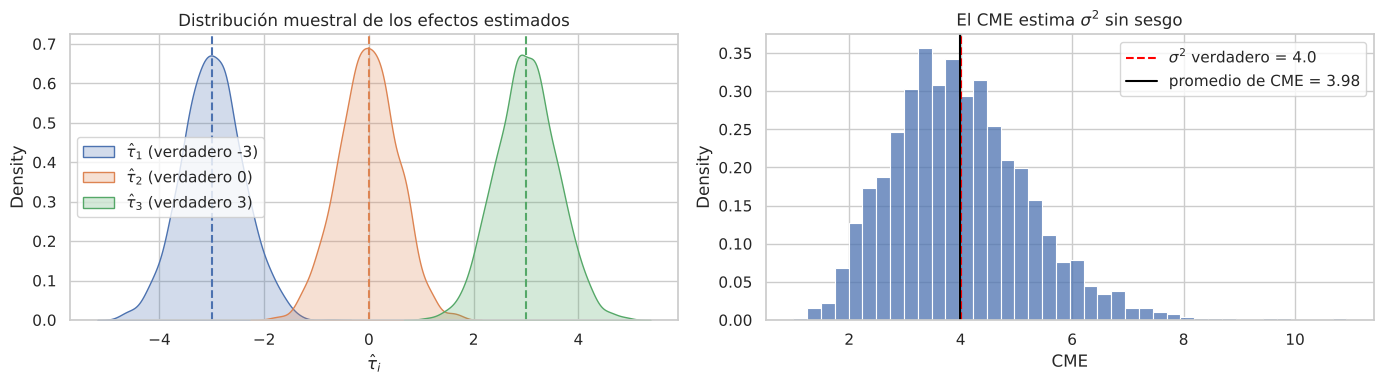

In [10]:
mu, tau, sigma, n_g = 20, np.array([-3, 0, 3]), 2.0, 8      # ✏️ cambie sigma o n_g y observe
reps = 2000
estim = np.empty((reps, 3)); cme = np.empty(reps)
for r in range(reps):
    y = np.concatenate([mu + t + rng.normal(0, sigma, n_g) for t in tau])
    g = np.repeat([0, 1, 2], n_g)
    medias_g = np.array([y[g == i].mean() for i in range(3)])
    estim[r] = medias_g - medias_g.mean()                     # tau estimado (restricción suma cero)
    cme[r] = sum(((y[g == i] - medias_g[i]) ** 2).sum() for i in range(3)) / (len(y) - 3)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for i in range(3):
    sns.kdeplot(estim[:, i], ax=axes[0], fill=True, label=fr"$\hat\tau_{i+1}$ (verdadero {tau[i]})")
    axes[0].axvline(tau[i], color=f"C{i}", ls="--")
axes[0].set(title="Distribución muestral de los efectos estimados", xlabel=r"$\hat\tau_i$"); axes[0].legend()
sns.histplot(cme, ax=axes[1], stat="density", bins=40)
axes[1].axvline(sigma**2, color="red", ls="--", label=fr"$\sigma^2$ verdadero = {sigma**2}")
axes[1].axvline(cme.mean(), color="black", label=f"promedio de CME = {cme.mean():.2f}")
axes[1].set(title=r"El CME estima $\sigma^2$ sin sesgo", xlabel="CME"); axes[1].legend()
plt.tight_layout(); plt.show()

**Cuando la estructura es correcta**, los estimadores se centran en los valores verdaderos (son **insesgados**) y el cuadrado medio del error (CME) estima $\sigma^2$. Esa es la base de toda generalización desde la muestra a la población. En la Unidad 4 veremos qué ocurre cuando la estructura **no** es correcta.

---
# UNIDAD 3. Análisis de varianza: la descomposición de la variabilidad

## 3.1 Notación

| Símbolo | Significado |
|---|---|
| $\bar y_{i\cdot}=\frac{1}{n_i}\sum_j y_{ij}$ | media del grupo $i$ |
| $\bar y_{\cdot\cdot}=\frac{1}{N}\sum_i\sum_j y_{ij}$ | media general |

## 3.2 La identidad fundamental

Cada desviación respecto a la media general se parte en dos:

$$
\underbrace{(y_{ij}-\bar y_{\cdot\cdot})}_{\text{total}}=\underbrace{(\bar y_{i\cdot}-\bar y_{\cdot\cdot})}_{\text{entre grupos}}+\underbrace{(y_{ij}-\bar y_{i\cdot})}_{\text{dentro del grupo}}
$$

Al elevar al cuadrado y sumar, el término cruzado se anula (porque $\sum_j(y_{ij}-\bar y_{i\cdot})=0$), y queda:

$$
\boxed{\;SC_T = SC_{Tr} + SC_E\;}
$$

$$
\sum_{i}\sum_{j}(y_{ij}-\bar y_{\cdot\cdot})^2=\sum_i n_i(\bar y_{i\cdot}-\bar y_{\cdot\cdot})^2+\sum_i\sum_j(y_{ij}-\bar y_{i\cdot})^2
$$

## 3.3 La tabla ANOVA

| Fuente | Suma de cuadrados | gl | Cuadrado medio | $F$ |
|---|---|---|---|---|
| Tratamientos (entre) | $SC_{Tr}$ | $k-1$ | $CM_{Tr}=SC_{Tr}/(k-1)$ | $F=CM_{Tr}/CM_E$ |
| Error (dentro) | $SC_E$ | $N-k$ | $CM_E=SC_E/(N-k)$ | |
| Total | $SC_T$ | $N-1$ | | |

### ¿Por qué el cociente $F$ tiene sentido? Los cuadrados medios esperados

$$
E(CM_E)=\sigma^2,\qquad E(CM_{Tr})=\sigma^2+\frac{\sum_i n_i\tau_i^2}{k-1}.
$$

- Si $H_0$ es cierta ($\tau_i=0$), **ambos** estiman $\sigma^2$ → $F\approx1$.
- Si $H_0$ es falsa, el numerador crece → $F>1$.

## 3.4 Cálculo paso a paso con `Cars93`

In [11]:
y, g = cars.logPrice, cars.Type
N, k = len(y), g.nunique()
media_general = y.mean()
resumen = cars.groupby("Type", observed=True).logPrice.agg(n_i="count", media_i="mean")

# Suma de cuadrados ENTRE grupos (tratamientos)
resumen["n_i*(media_i - media_general)^2"] = resumen.n_i * (resumen.media_i - media_general) ** 2
SC_Tr = resumen["n_i*(media_i - media_general)^2"].sum()

# Suma de cuadrados DENTRO de los grupos (error)
media_de_su_grupo = g.map(resumen.media_i).astype(float)
SC_E = ((y - media_de_su_grupo) ** 2).sum()

# Suma de cuadrados TOTAL
SC_T = ((y - media_general) ** 2).sum()

print(f"Media general = {media_general:.4f}   N = {N}   k = {k}\n")
display(resumen.round(4))
print(f"SC_Tr = {SC_Tr:.4f}")
print(f"SC_E  = {SC_E:.4f}")
print(f"SC_T  = {SC_T:.4f}    ¿SC_Tr + SC_E = SC_T?  {np.isclose(SC_Tr + SC_E, SC_T)}")

Media general = 2.8655   N = 93   k = 6



,n_i,media_i,n_i*(media_i - media_general)^2
Type,,,
Small,21,2.3029,6.6464
Compact,16,2.8443,0.0071
Midsize,22,3.2168,2.7157
Large,11,3.1626,0.9713
Sporty,14,2.8965,0.0135
Van,9,2.9454,0.0575


SC_Tr = 10.4115
SC_E  = 8.6085
SC_T  = 19.0200    ¿SC_Tr + SC_E = SC_T?  True


In [12]:
gl_Tr, gl_E = k - 1, N - k
CM_Tr, CM_E = SC_Tr / gl_Tr, SC_E / gl_E
F_obs = CM_Tr / CM_E
p_valor = stats.f.sf(F_obs, gl_Tr, gl_E)

tabla_anova = pd.DataFrame({
    "SC": [SC_Tr, SC_E, SC_T], "gl": [gl_Tr, gl_E, N - 1],
    "CM": [CM_Tr, CM_E, np.nan], "F": [F_obs, np.nan, np.nan], "p-valor": [p_valor, np.nan, np.nan]},
    index=["Tipo (entre)", "Error (dentro)", "Total"])
print("TABLA ANOVA construida a mano")
tabla_anova

TABLA ANOVA construida a mano


,SC,gl,CM,F,p-valor
Tipo (entre),10.4115,5,2.0823,21.0444,9.9008e-14
Error (dentro),8.6085,87,0.0989,NaN,NaN
Total,19.0200,92,NaN,NaN,NaN


In [13]:
# Verificación con dos librerías
print("statsmodels:")
print(sm.stats.anova_lm(m_ref))
print("\nscipy.stats.f_oneway:")
print(stats.f_oneway(*[d.logPrice for _, d in cars.groupby("Type", observed=True)]))

statsmodels:
            df   sum_sq  mean_sq        F      PR(>F)
C(Type)    5.0  10.4115   2.0823  21.0444  9.9008e-14
Residual  87.0   8.6085   0.0989      NaN         NaN

scipy.stats.f_oneway:
F_onewayResult(statistic=np.float64(21.04443583213054), pvalue=np.float64(9.900837193959494e-14))


✔ Los tres cálculos coinciden.

## 3.5 Visualizar la descomposición

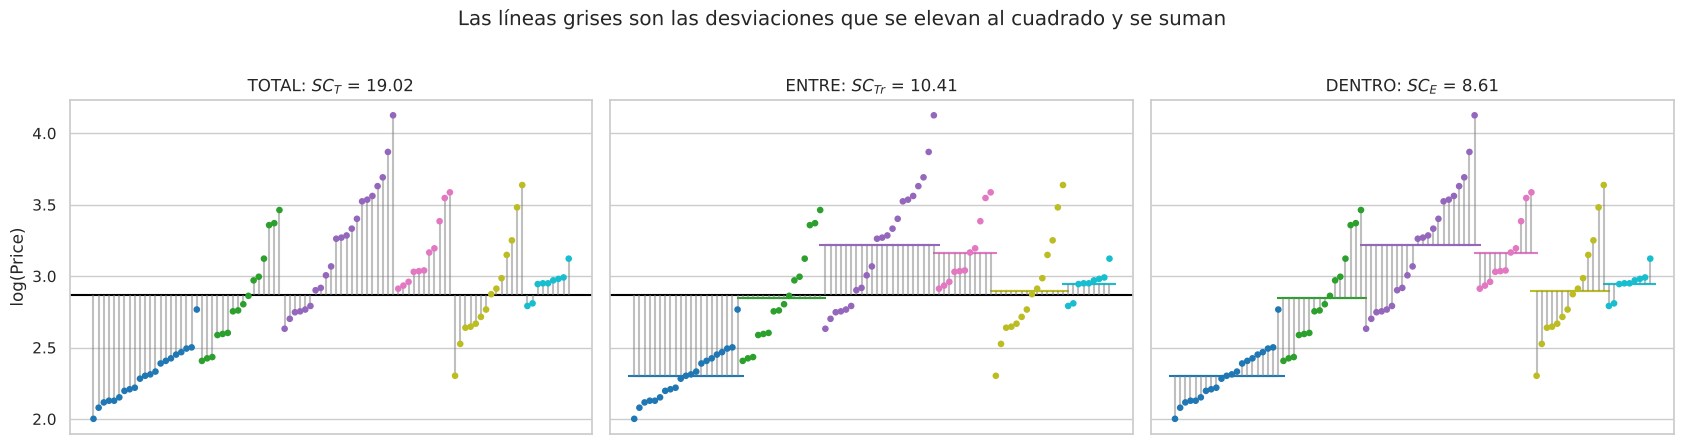

In [14]:
orden = cars.sort_values(["Type", "logPrice"]).reset_index(drop=True)
orden["media_grupo"] = orden.Type.map(resumen.media_i).astype(float)
x = np.arange(len(orden))
colores = orden.Type.cat.codes

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
titulos = [f"TOTAL: $SC_T$ = {SC_T:.2f}", f"ENTRE: $SC_{{Tr}}$ = {SC_Tr:.2f}", f"DENTRO: $SC_E$ = {SC_E:.2f}"]
for ax, t in zip(axes, titulos):
    ax.scatter(x, orden.logPrice, c=colores, cmap="tab10", s=14, zorder=3)
    ax.set_title(t); ax.set_xticks([])
axes[0].axhline(media_general, color="black")
axes[0].vlines(x, media_general, orden.logPrice, color="gray", alpha=.5)
axes[1].axhline(media_general, color="black")
axes[1].vlines(x, media_general, orden.media_grupo, color="gray", alpha=.5)
axes[1].scatter(x, orden.media_grupo, c=colores, cmap="tab10", marker="_", s=80)
axes[2].vlines(x, orden.media_grupo, orden.logPrice, color="gray", alpha=.5)
axes[2].scatter(x, orden.media_grupo, c=colores, cmap="tab10", marker="_", s=80)
axes[0].set_ylabel("log(Price)")
plt.suptitle("Las líneas grises son las desviaciones que se elevan al cuadrado y se suman", y=1.03)
plt.tight_layout(); plt.show()

## 3.6 Tamaño del efecto: ¿qué tan grande es la diferencia?

Un $p$-valor pequeño dice que hay diferencias, **no** qué tan importantes son. Para eso:

$$
\eta^2=\frac{SC_{Tr}}{SC_T}\qquad\qquad \omega^2=\frac{SC_{Tr}-(k-1)CM_E}{SC_T+CM_E}
$$

$\eta^2$ es el $R^2$ del modelo (proporción de variabilidad explicada por el factor); $\omega^2$ corrige su sesgo optimista. Guía orientativa (Cohen): 0.01 pequeño, 0.06 mediano, 0.14 grande.

In [15]:
eta2 = SC_Tr / SC_T
omega2 = (SC_Tr - gl_Tr * CM_E) / (SC_T + CM_E)
print(f"η² = {eta2:.3f}   (coincide con el R² del modelo: {m_ref.rsquared:.3f})")
print(f"ω² = {omega2:.3f}")

η² = 0.547   (coincide con el R² del modelo: 0.547)
ω² = 0.519


El tipo de vehículo explica cerca del **55 %** de la variabilidad del logaritmo del precio: un efecto **muy grande**.

---
# UNIDAD 4. Pruebas de hipótesis

## 4.1 Planteamiento

$$
H_0:\ \mu_1=\mu_2=\cdots=\mu_k\quad(\Leftrightarrow\ \tau_1=\cdots=\tau_k=0)
\qquad\text{vs.}\qquad
H_1:\ \text{al menos una } \mu_i \text{ es distinta}
$$

> ⚠️ $H_1$ **no** dice "todas son distintas". Rechazar $H_0$ sólo indica que **alguna** difiere; cuál(es), lo dicen las comparaciones múltiples (4.5).

Bajo $H_0$ **y los supuestos del modelo**, $F\sim F_{k-1,\,N-k}$. Rechazamos $H_0$ si $F_{obs}>F_{\alpha;\,k-1,\,N-k}$, o equivalentemente si $p<\alpha$.

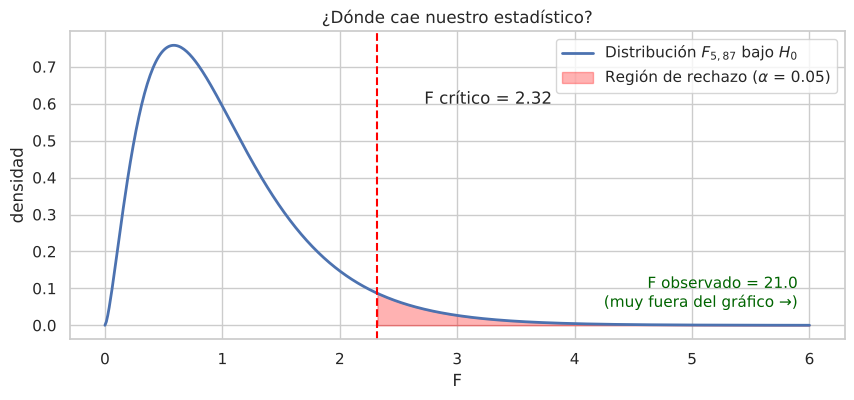

F observado = 21.04  >  F crítico = 2.32   ->   p = 9.90e-14.  Se rechaza H0.


In [16]:
alfa = 0.05
F_crit = stats.f.ppf(1 - alfa, gl_Tr, gl_E)
xs = np.linspace(0, 6, 500)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(xs, stats.f.pdf(xs, gl_Tr, gl_E), lw=2, label=fr"Distribución $F_{{{gl_Tr},{gl_E}}}$ bajo $H_0$")
ax.fill_between(xs, stats.f.pdf(xs, gl_Tr, gl_E), where=xs >= F_crit, color="red", alpha=.3,
                label=fr"Región de rechazo ($\alpha$ = {alfa})")
ax.axvline(F_crit, color="red", ls="--")
ax.annotate(f"F crítico = {F_crit:.2f}", (F_crit, .55), xytext=(F_crit + .4, .6), arrowprops=dict(arrowstyle="->"))
ax.annotate(f"F observado = {F_obs:.1f}\n(muy fuera del gráfico →)", (5.9, .05), ha="right", color="darkgreen", fontsize=11)
ax.set(xlabel="F", ylabel="densidad", title="¿Dónde cae nuestro estadístico?"); ax.legend(); plt.show()
print(f"F observado = {F_obs:.2f}  >  F crítico = {F_crit:.2f}   ->   p = {p_valor:.2e}.  Se rechaza H0.")

**Conclusión (provisional):** hay evidencia muy fuerte de que el precio medio (en escala log) **no es igual** en todos los tipos de vehículo.

¿Por qué "provisional"? Porque la distribución $F$ **sólo es válida si se cumple la estructura del modelo**. Antes de concluir, verificamos los supuestos.

## 4.2 Verificación de supuestos

Los supuestos se verifican sobre los **residuos** $e_{ij}=y_{ij}-\bar y_{i\cdot}$.

Comparamos dos opciones de respuesta: `Price` en su escala original y `log(Price)`.

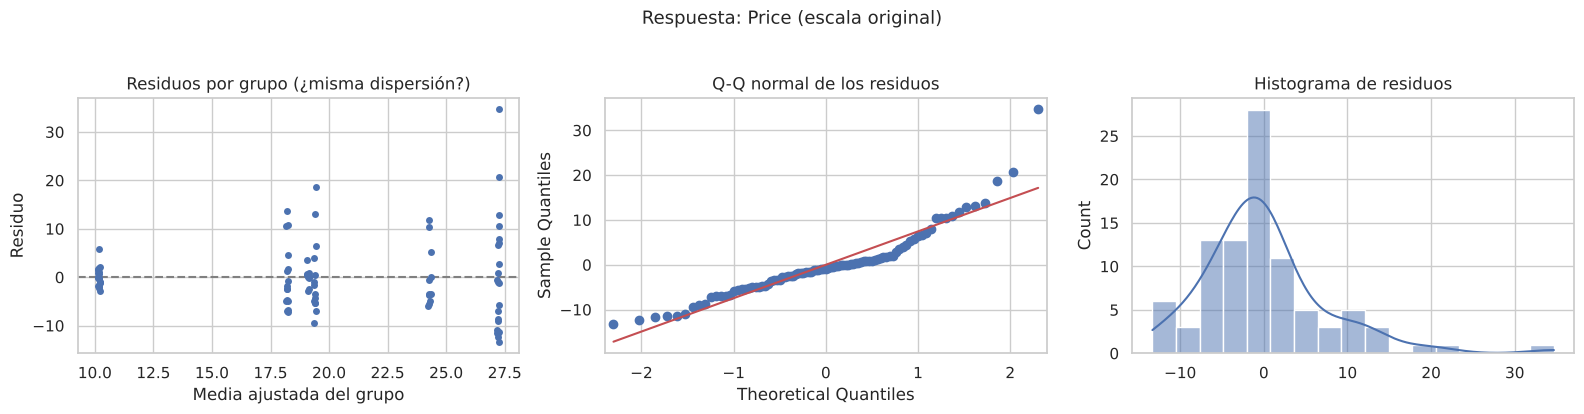

Shapiro-Wilk (H0: normalidad):              p = 0.0000
Levene, mediana (H0: varianzas iguales):    p = 0.0001
Bartlett (H0: varianzas iguales; exige normalidad): p = 0.0000
Razón DE máxima / DE mínima: 6.5   (regla práctica: preocupa si > 2–3)


In [17]:
def diagnostico_anova(formula, datos, factor, titulo):
    m = smf.ols(formula, data=datos).fit()
    grupos = [r for _, r in m.resid.groupby(datos[factor], observed=True)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    sns.stripplot(x=m.fittedvalues.round(3), y=m.resid, ax=axes[0], jitter=.2, native_scale=True)
    axes[0].axhline(0, ls="--", c="gray")
    axes[0].set(xlabel="Media ajustada del grupo", ylabel="Residuo", title="Residuos por grupo (¿misma dispersión?)")
    sm.qqplot(m.resid, line="s", ax=axes[1]); axes[1].set_title("Q-Q normal de los residuos")
    sns.histplot(m.resid, kde=True, ax=axes[2]); axes[2].set_title("Histograma de residuos")
    plt.suptitle(titulo, y=1.03, fontsize=13); plt.tight_layout(); plt.show()

    de = datos.groupby(factor, observed=True)[formula.split("~")[0].strip()].std()
    print(f"Shapiro-Wilk (H0: normalidad):              p = {stats.shapiro(m.resid).pvalue:.4f}")
    print(f"Levene, mediana (H0: varianzas iguales):    p = {stats.levene(*grupos, center='median').pvalue:.4f}")
    print(f"Bartlett (H0: varianzas iguales; exige normalidad): p = {stats.bartlett(*grupos).pvalue:.4f}")
    print(f"Razón DE máxima / DE mínima: {de.max() / de.min():.1f}   (regla práctica: preocupa si > 2–3)")
    return m

_ = diagnostico_anova("Price ~ C(Type)", cars, "Type", "Respuesta: Price (escala original)")

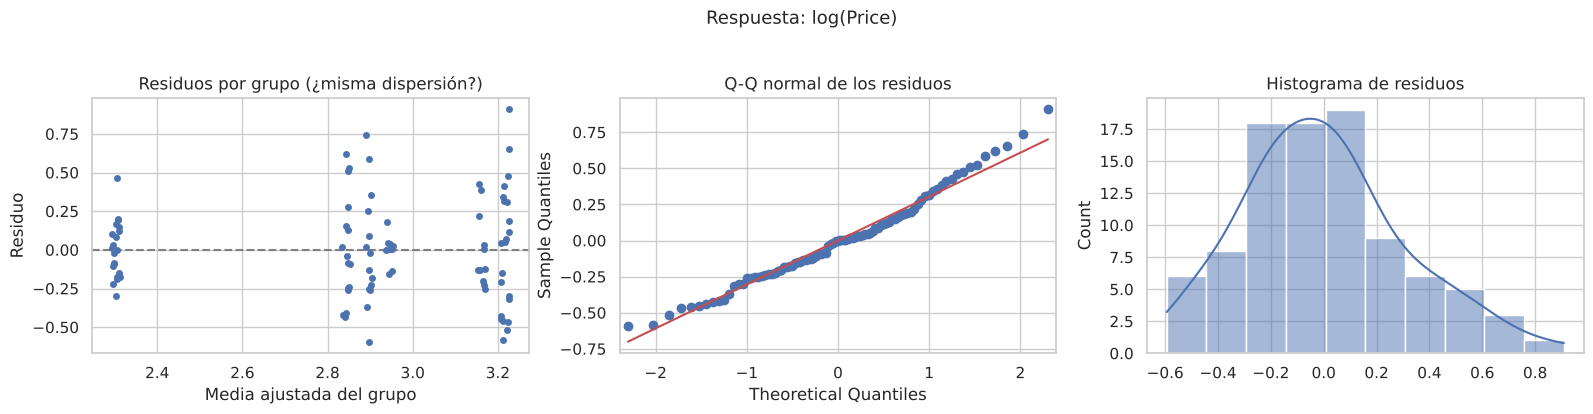

Shapiro-Wilk (H0: normalidad):              p = 0.1299
Levene, mediana (H0: varianzas iguales):    p = 0.0009
Bartlett (H0: varianzas iguales; exige normalidad): p = 0.0001
Razón DE máxima / DE mínima: 4.3   (regla práctica: preocupa si > 2–3)


In [18]:
_ = diagnostico_anova("logPrice ~ C(Type)", cars, "Type", "Respuesta: log(Price)")

### Lectura del diagnóstico

| | `Price` | `log(Price)` |
|---|---|---|
| Normalidad | Se rechaza (cola derecha larga) | **Aceptable** |
| Homocedasticidad | Se rechaza fuertemente; los grupos caros son muchísimo más dispersos | Mejora, pero aún **no** es homogénea (las *vans* son muy parecidas entre sí) |

El logaritmo resuelve la normalidad y reduce la heterogeneidad, pero **no la elimina**. ¿Es grave? Depende… y para responder con honestidad usamos **simulación**.

> 📌 **Independencia:** no se prueba con un test; se justifica por el **diseño** (cada auto es un modelo distinto, medido una vez). Si hubiera medidas repetidas o datos en el tiempo, habría que usar otros modelos.

## 4.3 🔬 ¿Qué pasa cuando la estructura no se cumple? (simulación de robustez)

Simulamos 3 grupos con **medias iguales** ($H_0$ verdadera), así que una prueba bien calibrada debería rechazar el **5 %** de las veces. Variamos los tamaños de muestra y las desviaciones estándar.

In [19]:
def tasa_rechazo(ns, sds, reps=3000, alfa=0.05, rng=rng):
    rech_F = rech_W = 0
    grupo = np.repeat(np.arange(len(ns)), ns)
    for _ in range(reps):
        y = np.concatenate([rng.normal(0, s, n) for n, s in zip(ns, sds)])
        muestras = [y[grupo == i] for i in range(len(ns))]
        rech_F += stats.f_oneway(*muestras).pvalue < alfa
        rech_W += anova_oneway(y, grupo, use_var="unequal").pvalue < alfa
    return rech_F / reps, rech_W / reps

escenarios = {
    "A. Todo se cumple (n iguales, σ iguales)":         ([20, 20, 20], [1, 1, 1]),
    "B. σ distintas, n iguales":                        ([20, 20, 20], [1, 2, 4]),
    "C. σ distintas; grupo GRANDE con σ grande":        ([10, 20, 40], [1, 2, 4]),
    "D. σ distintas; grupo PEQUEÑO con σ grande":       ([10, 20, 40], [4, 2, 1]),
}
filas = []
for nombre, (ns, sds) in escenarios.items():
    tF, tW = tasa_rechazo(ns, sds)
    filas.append({"escenario": nombre, "n": ns, "σ": sds, "Error tipo I: F clásica": tF, "Error tipo I: Welch": tW})
robustez = pd.DataFrame(filas)
robustez.style.format({"Error tipo I: F clásica": "{:.3f}", "Error tipo I: Welch": "{:.3f}"}) \
    .background_gradient(subset=["Error tipo I: F clásica", "Error tipo I: Welch"], cmap="Reds", vmin=0, vmax=.25)

,escenario,n,σ,Error tipo I: F clásica,Error tipo I: Welch
0,"A. Todo se cumple (n iguales, σ iguales)","[20, 20, 20]","[1, 1, 1]",0.045,0.043
1,"B. σ distintas, n iguales","[20, 20, 20]","[1, 2, 4]",0.066,0.045
2,C. σ distintas; grupo GRANDE con σ grande,"[10, 20, 40]","[1, 2, 4]",0.010,0.056
3,D. σ distintas; grupo PEQUEÑO con σ grande,"[10, 20, 40]","[4, 2, 1]",0.248,0.061


### Lo que nos enseña la simulación

- **A:** con la estructura correcta, ambas pruebas rechazan ≈5 %: están **calibradas**.
- **B:** con diseño **balanceado**, la $F$ clásica tolera bastante bien varianzas distintas.
- **C:** si el grupo grande es el más disperso, la $F$ se vuelve **conservadora** (rechaza menos de lo debido → pierde potencia).
- **D:** si el grupo **pequeño** es el más disperso, la $F$ se vuelve **liberal**: ¡rechaza $H_0$ verdadera muchas más veces de lo prometido! Sus "descubrimientos" no son confiables.
- La prueba de **Welch** se mantiene cerca del 5 % en todos los casos.

> 🔒 **Esto es la rigidez de la estructura paramétrica en acción:** el $p$-valor de la $F$ clásica es una promesa ("me equivoco el 5 % de las veces") que **sólo se cumple si el modelo es correcto**. Cuando no lo es, la promesa se rompe, y las generalizaciones deben moderarse o hacerse con una estructura más flexible.

✏️ **Experimente:** agregue un escenario con `([5, 5, 50], [3, 1, 1])`. ¿Qué espera que ocurra?

## 4.4 Alternativas cuando los supuestos fallan

| Situación | Alternativa | Qué relaja |
|---|---|---|
| Varianzas desiguales | **ANOVA de Welch** | Permite un $\sigma_i^2$ distinto por grupo |
| Asimetría, varianza que crece con la media | **Transformación** (log, raíz) | Cambia la escala para que la estructura se cumpla |
| No normalidad severa, atípicos | **Kruskal-Wallis** | No supone normalidad; compara distribuciones (rangos) |
| Varianza desigual + necesidad de coeficientes | Errores estándar robustos (HC3) | Corrige la inferencia de la regresión |

Apliquemos todas a `Cars93`:

In [20]:
grupos_log = [d.logPrice.values for _, d in cars.groupby("Type", observed=True)]
grupos_raw = [d.Price.values for _, d in cars.groupby("Type", observed=True)]

welch = anova_oneway(cars.logPrice, cars.Type, use_var="unequal")
kw = stats.kruskal(*grupos_raw)          # basado en rangos: da igual usar Price o log(Price)

pd.DataFrame({
    "Prueba": ["F clásica (log Price)", "Welch (log Price)", "Kruskal-Wallis (rangos)"],
    "Estadístico": [F_obs, welch.statistic, kw.statistic],
    "gl": [f"{gl_Tr}, {gl_E}", f"{welch.df_num:.0f}, {welch.df_denom:.1f}", f"{k-1} (χ²)"],
    "p-valor": [p_valor, welch.pvalue, kw.pvalue],
})

,Prueba,Estadístico,gl,p-valor
0,F clásica (log Price),21.0444,"5, 87",9.9008e-14
1,Welch (log Price),41.6834,"5, 36.8",3.6314e-14
2,Kruskal-Wallis (rangos),51.6585,5 (χ²),6.3386e-10


**Conclusión robusta:** las tres pruebas, con supuestos distintos, llevan a la **misma decisión**. Cuando métodos con estructuras diferentes coinciden, la conclusión es mucho más confiable.

## 4.5 Comparaciones múltiples: ¿cuáles grupos difieren?

### Prueba de Tukey HSD
Compara **todos los pares** controlando la tasa de error de familia en $\alpha$. Es la elección estándar para comparaciones *post hoc*.

In [21]:
tukey = pairwise_tukeyhsd(cars.logPrice, cars.Type.astype(str), alpha=0.05)
print(tukey.summary())

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower   upper  reject
------------------------------------------------------
Compact   Large   0.3183 0.1124 -0.0408  0.6773  False
Compact Midsize   0.3725 0.0067  0.0713  0.6737   True
Compact   Small  -0.5414    0.0 -0.8456 -0.2372   True
Compact  Sporty   0.0522 0.9975 -0.2833  0.3877  False
Compact     Van   0.1011 0.9717 -0.2809   0.483  False
  Large Midsize   0.0542 0.9972 -0.2843  0.3927  False
  Large   Small  -0.8597    0.0 -1.2009 -0.5185   True
  Large  Sporty  -0.2661 0.2972 -0.6354  0.1032  False
  Large     Van  -0.2172  0.642 -0.6292  0.1948  False
Midsize   Small  -0.9139    0.0 -1.1936 -0.6343   True
Midsize  Sporty  -0.3203 0.0422 -0.6337 -0.0069   True
Midsize     Van  -0.2714 0.2574 -0.6341  0.0913  False
  Small  Sporty   0.5936    0.0  0.2773  0.9099   True
  Small     Van   0.6425    0.0  0.2773  1.0077   True
 Sporty     Van   0.0489 0.9991 -0.3428  0.4405  False
----------

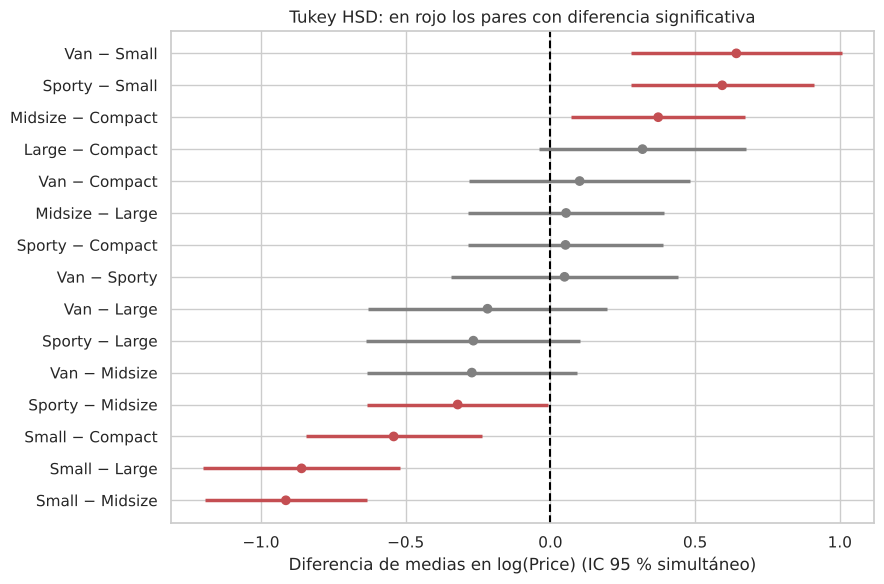

In [22]:
res_t = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
res_t["par"] = res_t.group2 + " − " + res_t.group1        # meandiff = media(group2) − media(group1)
res_t = res_t.sort_values("meandiff")

fig, ax = plt.subplots(figsize=(9, 6))
col = np.where(res_t.reject, "C3", "gray")
ax.hlines(res_t.par, res_t.lower, res_t.upper, color=col, lw=2.5)
ax.scatter(res_t.meandiff, res_t.par, color=col, zorder=3)
ax.axvline(0, ls="--", c="black")
ax.set(xlabel="Diferencia de medias en log(Price) (IC 95 % simultáneo)",
       title="Tukey HSD: en rojo los pares con diferencia significativa")
plt.tight_layout(); plt.show()

**Interpretación en escala original.** Una diferencia $d$ en logaritmos equivale a una **razón** $e^{d}$ entre precios (medias geométricas). Por ejemplo, si *Midsize – Small* ≈ 0.91, un mediano cuesta en promedio $e^{0.91}\approx 2.5$ veces lo que cuesta un pequeño.

Resumen: los **pequeños** son más baratos que todos los demás tipos; **Midsize** es más caro que Compact y Sporty; los demás pares no muestran diferencias claras.

### Contrastes planeados

Si **antes** de ver los datos tenemos una pregunta específica, se formula como un **contraste** $L=\sum c_i\mu_i$ con $\sum c_i=0$. Ejemplo: *¿los vehículos "familiares" (Midsize, Large, Van) cuestan distinto que los "urbanos" (Small, Compact)?*

$$L=\tfrac13(\mu_{Mid}+\mu_{Lar}+\mu_{Van})-\tfrac12(\mu_{Sma}+\mu_{Com})$$

In [23]:
m_celdas = smf.ols("logPrice ~ C(Type) - 1", data=cars).fit()      # modelo de medias de celda (sin intercepto)
print(m_celdas.params.round(4).to_string(), "\n")
c = np.array([-1/2, -1/2, 1/3, 1/3, 0, 1/3])                         # orden: Small, Compact, Midsize, Large, Sporty, Van
contraste = m_celdas.t_test(c)
print(contraste)
print(f"\nEstimación del contraste: {contraste.effect[0]:.3f}  ->  los familiares cuestan ≈ {np.exp(contraste.effect[0]):.2f} veces más")

C(Type)[Small]      2.3029
C(Type)[Compact]    2.8443
C(Type)[Midsize]    3.2168
C(Type)[Large]      3.1626
C(Type)[Sporty]     2.8965
C(Type)[Van]        2.9454 

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.5347      0.074      7.246      0.000       0.388       0.681

Estimación del contraste: 0.535  ->  los familiares cuestan ≈ 1.71 veces más


### Bonferroni (alternativa sencilla)
Si se hacen $m$ comparaciones, se usa $\alpha/m$ en cada una. Es más conservadora que Tukey cuando se comparan todos los pares, pero sirve para cualquier conjunto de comparaciones.

| Método | Cuándo usarlo |
|---|---|
| **Tukey HSD** | Todos los pares, después del ANOVA |
| **Bonferroni** | Pocas comparaciones específicas |
| **Contrastes planeados** | Preguntas definidas **antes** de ver los datos |
| **Dunnett** | Cada tratamiento contra un control |
| **Games-Howell** | Todos los pares con varianzas desiguales |

## 4.6 Potencia y tamaño de muestra

Antes de un experimento conviene preguntarse: *¿cuántas réplicas necesito para detectar una diferencia relevante?* La potencia depende de $\alpha$, del número de grupos, del tamaño de muestra y del tamaño del efecto $f=\sqrt{\eta^2/(1-\eta^2)}$ (Cohen: 0.10 pequeño, 0.25 mediano, 0.40 grande).

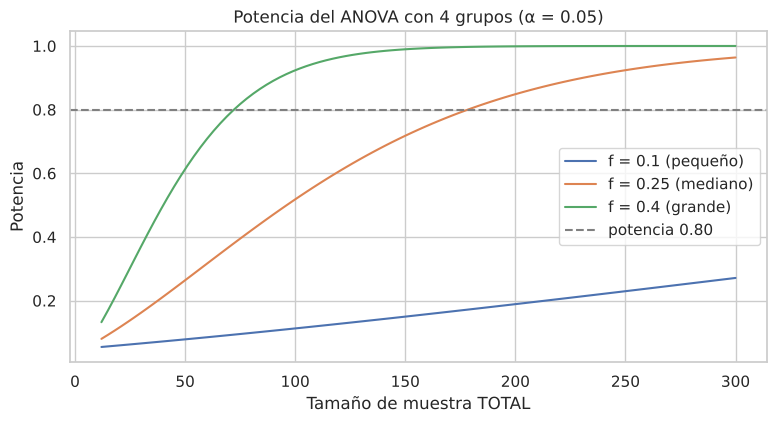

Efecto f = 0.25: se necesitan ≈ 179 observaciones en total (45 por grupo)
Efecto f = 0.4: se necesitan ≈ 73 observaciones en total (19 por grupo)


In [24]:
potencia = FTestAnovaPower()
n_total = np.arange(12, 301, 3)
plt.figure(figsize=(9, 4.3))
for f, et in zip([0.10, 0.25, 0.40], ["pequeño", "mediano", "grande"]):
    plt.plot(n_total, potencia.power(effect_size=f, nobs=n_total, alpha=0.05, k_groups=4), label=f"f = {f} ({et})")
plt.axhline(0.8, ls="--", color="gray", label="potencia 0.80")
plt.xlabel("Tamaño de muestra TOTAL"); plt.ylabel("Potencia"); plt.title("Potencia del ANOVA con 4 grupos (α = 0.05)")
plt.legend(); plt.show()

for f in [0.25, 0.40]:
    n_req = potencia.solve_power(effect_size=f, alpha=0.05, power=0.80, k_groups=4)
    print(f"Efecto f = {f}: se necesitan ≈ {np.ceil(n_req):.0f} observaciones en total ({np.ceil(n_req/4):.0f} por grupo)")

---
# UNIDAD 5. Extensiones del modelo ANOVA

El modelo de un factor es el caso más simple de una familia muy amplia. Cada extensión **agrega estructura** para representar mejor la realidad (y cada estructura nueva trae sus propios supuestos).

## 5.1 ANOVA de dos factores con interacción

### El modelo
$$
y_{ijk}=\mu+\alpha_i+\beta_j+(\alpha\beta)_{ij}+\varepsilon_{ijk},\qquad \varepsilon_{ijk}\sim N(0,\sigma^2)
$$

- $\alpha_i$: efecto principal del factor A (nivel $i$).
- $\beta_j$: efecto principal del factor B (nivel $j$).
- $(\alpha\beta)_{ij}$: **interacción**: el efecto de A **depende** del nivel de B.

### Ejemplo: un experimento industrial (datos simulados)

Una planta quiere maximizar el **rendimiento (%)** de un proceso químico. Se prueban 3 temperaturas × 2 catalizadores, con 4 réplicas por combinación asignadas **al azar** (24 corridas). Como los datos son simulados, **conocemos la verdad**: el catalizador B sólo es mejor a temperatura alta.

In [25]:
rng2 = np.random.default_rng(11)
medias_celda = pd.DataFrame({"A": [70, 75, 77], "B": [69, 76, 85]}, index=["Baja", "Media", "Alta"])  # verdad
filas = []
for temp in medias_celda.index:
    for cat in medias_celda.columns:
        for r in range(4):
            filas.append({"Temperatura": temp, "Catalizador": cat,
                          "Rendimiento": medias_celda.loc[temp, cat] + rng2.normal(0, 2.5)})
proceso = pd.DataFrame(filas)
proceso["Temperatura"] = pd.Categorical(proceso.Temperatura, ["Baja", "Media", "Alta"])
print("Medias VERDADERAS (desconocidas en la práctica):"); display(medias_celda)
print("Réplicas por celda (diseño balanceado):"); display(pd.crosstab(proceso.Temperatura, proceso.Catalizador))

Medias VERDADERAS (desconocidas en la práctica):


,A,B
Baja,70,69
Media,75,76
Alta,77,85


Réplicas por celda (diseño balanceado):


Catalizador,A,B
Temperatura,,
Baja,4,4
Media,4,4
Alta,4,4


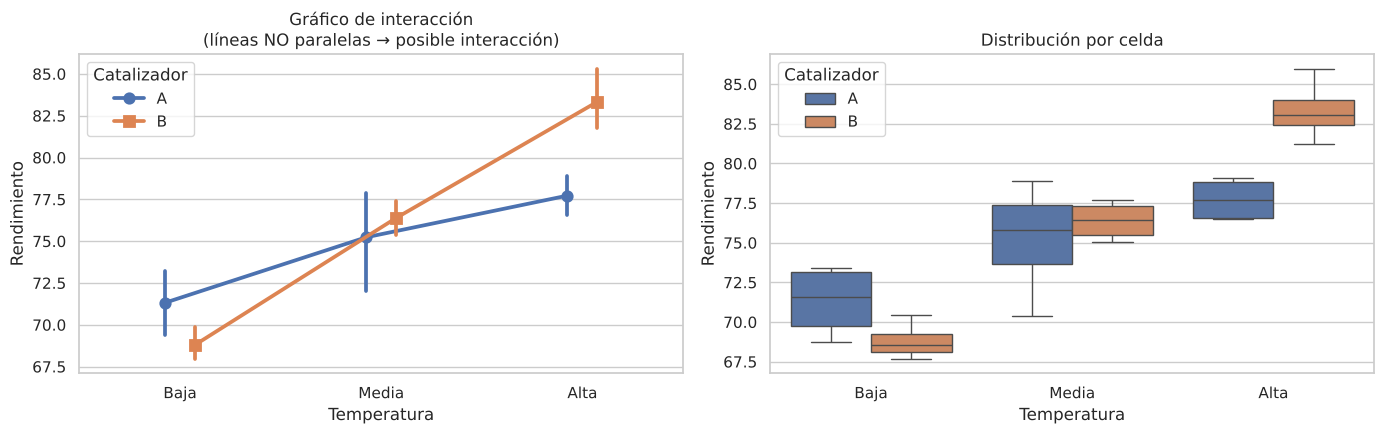

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.pointplot(data=proceso, x="Temperatura", y="Rendimiento", hue="Catalizador", errorbar=("ci", 95),
              dodge=.15, markers=["o", "s"], ax=axes[0])
axes[0].set_title("Gráfico de interacción\n(líneas NO paralelas → posible interacción)")
sns.boxplot(data=proceso, x="Temperatura", y="Rendimiento", hue="Catalizador", ax=axes[1])
axes[1].set_title("Distribución por celda")
plt.tight_layout(); plt.show()

In [27]:
m2 = smf.ols("Rendimiento ~ C(Temperatura) * C(Catalizador)", data=proceso).fit()
print(sm.stats.anova_lm(m2, typ=2))

                                 sum_sq    df        F      PR(>F)
C(Temperatura)                 439.7458   2.0  48.4179  5.7116e-08
C(Catalizador)                  12.1229   1.0   2.6696  1.1965e-01
C(Temperatura):C(Catalizador)   66.2678   2.0   7.2964  4.7793e-03
Residual                        81.7407  18.0      NaN         NaN


### ¿Cómo se lee?

1. **Primero la interacción.** Si es significativa, los efectos principales **no** se interpretan solos: "el catalizador B es mejor" sería falso a temperatura baja.
2. Con interacción, se analizan los **efectos simples**: comparar catalizadores **dentro de cada** temperatura.

In [28]:
filas = []
for temp, d in proceso.groupby("Temperatura", observed=True):
    a, b = d[d.Catalizador == "A"].Rendimiento, d[d.Catalizador == "B"].Rendimiento
    t = stats.ttest_ind(b, a)
    filas.append({"Temperatura": temp, "media A": a.mean(), "media B": b.mean(), "B − A": b.mean() - a.mean(),
                  "p (Bonferroni ×3)": min(1, 3 * t.pvalue)})
pd.DataFrame(filas).round(3)

,Temperatura,media A,media B,B − A,p (Bonferroni ×3)
0,Baja,71.318,68.805,-2.513,0.295
1,Media,75.231,76.392,1.161,1.000
2,Alta,77.722,83.337,5.615,0.010


**Conclusión práctica:** a temperatura **alta**, el catalizador B rinde claramente más; a temperaturas baja y media no hay diferencias relevantes. La recomendación es *temperatura alta + catalizador B*.

> 🔒 **Rigidez:** si hubiéramos ajustado un modelo **aditivo** (sin interacción: `A + B`), le habríamos impuesto a los datos que el efecto del catalizador es **el mismo** a toda temperatura. El modelo habría "promediado" y la conclusión habría sido engañosa.

## 5.2 Diseños desbalanceados: sumas de cuadrados Tipo I, II y III

Cuando las celdas tienen distinto número de observaciones, los factores dejan de ser **ortogonales** y la variabilidad se puede repartir de varias maneras:

| Tipo | Cómo se calcula | Cuándo usar |
|---|---|---|
| **I** (secuencial) | Cada término ajustado por los **anteriores** | Cuando hay un orden natural; depende del orden en la fórmula |
| **II** | Cada efecto principal ajustado por los otros principales (sin la interacción) | Si la interacción no es relevante |
| **III** | Cada término ajustado por **todos** los demás | Con interacción; requiere contrastes de suma cero |

Ejemplo real con `Cars93`: `log(Price)` según **origen** y **tracción** (celdas desbalanceadas).

In [29]:
display(pd.crosstab(cars.DriveTrain, cars.Origin, margins=True))

m_AB = smf.ols("logPrice ~ C(Origin) * C(DriveTrain)", data=cars).fit()
m_BA = smf.ols("logPrice ~ C(DriveTrain) * C(Origin)", data=cars).fit()
m_III = smf.ols("logPrice ~ C(Origin, Sum) * C(DriveTrain, Sum)", data=cars).fit()

print("Tipo I, orden Origin → DriveTrain"); print(sm.stats.anova_lm(m_AB, typ=1).round(4))
print("\nTipo I, orden DriveTrain → Origin"); print(sm.stats.anova_lm(m_BA, typ=1).round(4))
print("\nTipo II"); print(sm.stats.anova_lm(m_AB, typ=2).round(4))
print("\nTipo III (contrastes de suma cero)"); print(sm.stats.anova_lm(m_III, typ=3).round(4))

Origin,USA,non-USA,All
DriveTrain,,,
4WD,5,5,10
Front,34,33,67
Rear,9,7,16
All,48,45,93


Tipo I, orden Origin → DriveTrain
                           df   sum_sq  mean_sq        F  PR(>F)
C(Origin)                 1.0   0.0429   0.0429   0.2573  0.6132
C(DriveTrain)             2.0   3.3410   1.6705  10.0267  0.0001
C(Origin):C(DriveTrain)   2.0   1.1414   0.5707   3.4255  0.0370
Residual                 87.0  14.4947   0.1666      NaN     NaN

Tipo I, orden DriveTrain → Origin
                           df   sum_sq  mean_sq       F  PR(>F)
C(DriveTrain)             2.0   3.3036   1.6518  9.9145  0.0001
C(Origin)                 1.0   0.0803   0.0803  0.4817  0.4895
C(DriveTrain):C(Origin)   2.0   1.1414   0.5707  3.4255  0.0370
Residual                 87.0  14.4947   0.1666     NaN     NaN

Tipo II
                          sum_sq    df        F  PR(>F)
C(Origin)                 0.0803   1.0   0.4817  0.4895
C(DriveTrain)             3.3410   2.0  10.0267  0.0001
C(Origin):C(DriveTrain)   1.1414   2.0   3.4255  0.0370
Residual                 14.4947  87.0      NaN     N

Observe que en **Tipo I** la suma de cuadrados de `Origin` **cambia según el orden**: con diseños desbalanceados, la pregunta "¿cuánto explica `Origin`?" depende de qué otras variables ya se tuvieron en cuenta. Esto es la misma lógica de la **selección de variables** en regresión: el aporte de una variable es siempre **parcial**.

### Un caso extremo: celdas vacías

In [30]:
pd.crosstab(cars.Type, cars.Origin)

Origin,USA,non-USA
Type,,
Small,7,14
Compact,7,9
Midsize,10,12
Large,11,0
Sporty,8,6
Van,5,4


No hay ningún auto **Large** de origen **non-USA**. Con una celda vacía, el parámetro de interacción $(\alpha\beta)_{\text{Large, non-USA}}$ **no es estimable**: no hay datos que lo informen. El modelo con interacción `Type * Origin` impone una estructura que los datos **no pueden sostener**, y cualquier "efecto" que el software reporte para esa celda es producto de la parametrización, no de la evidencia.

> 🔒 **Generalización responsable:** no podemos decir nada sobre autos grandes importados con estos datos.

## 5.3 Diseño en bloques completos al azar (DBCA)

Cuando existe una fuente de variabilidad **conocida pero no de interés** (operario, lote, día, máquina), se **bloquea**: cada bloque recibe todos los tratamientos.

$$y_{ij}=\mu+\tau_i+\beta_j+\varepsilon_{ij}$$

Ejemplo simulado: se comparan **4 métodos de ensamble** (tiempo en minutos); cada uno de **5 operarios** prueba los 4 métodos. Los operarios son muy distintos entre sí en rapidez.

In [31]:
rng3 = np.random.default_rng(5)
efecto_metodo = {"M1": 0, "M2": -1.5, "M3": -2.0, "M4": 0.5}
efecto_operario = {f"Op{j}": e for j, e in enumerate(rng3.normal(0, 4, 5), start=1)}   # ¡gran variación entre operarios!
bloques = pd.DataFrame([{"Metodo": m, "Operario": o, "Tiempo": 30 + em + eo + rng3.normal(0, 1)}
                        for m, em in efecto_metodo.items() for o, eo in efecto_operario.items()])

sin_bloque = smf.ols("Tiempo ~ C(Metodo)", data=bloques).fit()
con_bloque = smf.ols("Tiempo ~ C(Metodo) + C(Operario)", data=bloques).fit()
print("SIN considerar el bloque (ANOVA de un factor):"); print(sm.stats.anova_lm(sin_bloque).round(4))
print("\nCON bloque (DBCA):"); print(sm.stats.anova_lm(con_bloque).round(4))

SIN considerar el bloque (ANOVA de un factor):
             df    sum_sq  mean_sq      F  PR(>F)
C(Metodo)   3.0   35.4514  11.8171  0.624  0.6098
Residual   16.0  302.9953  18.9372    NaN     NaN

CON bloque (DBCA):
               df    sum_sq  mean_sq         F  PR(>F)
C(Metodo)     3.0   35.4514  11.8171   18.2837  0.0001
C(Operario)   4.0  295.2395  73.8099  114.2002  0.0000
Residual     12.0    7.7558   0.6463       NaN     NaN


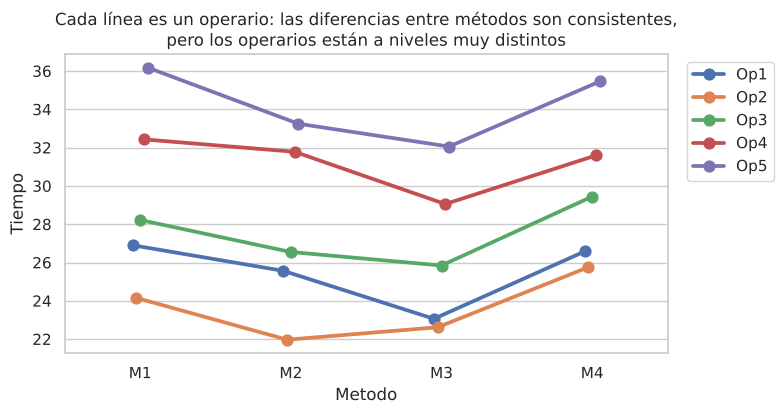

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.3))
sns.pointplot(data=bloques, x="Metodo", y="Tiempo", hue="Operario", ax=ax, dodge=.1, errorbar=None)
ax.set_title("Cada línea es un operario: las diferencias entre métodos son consistentes,\npero los operarios están a niveles muy distintos")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Sin bloquear**, la gran variabilidad entre operarios queda dentro del error y **esconde** el efecto del método. **Al bloquear**, esa variabilidad se separa, el $CM_E$ baja drásticamente y el efecto del método se vuelve evidente. Bloquear es "comparar a cada operario consigo mismo".

## 5.4 ANCOVA: agregar una covariable cuantitativa

¿Los autos grandes son más caros **por ser grandes** o porque tienen **motores más potentes**? El ANCOVA compara grupos **ajustando** por una variable continua:

$$y_{ij}=\mu+\tau_i+\gamma\,(x_{ij}-\bar x)+\varepsilon_{ij}$$

Supuesto adicional (otra "rigidez"): **pendientes homogéneas**, la relación entre $x$ y $y$ es la misma en todos los grupos.

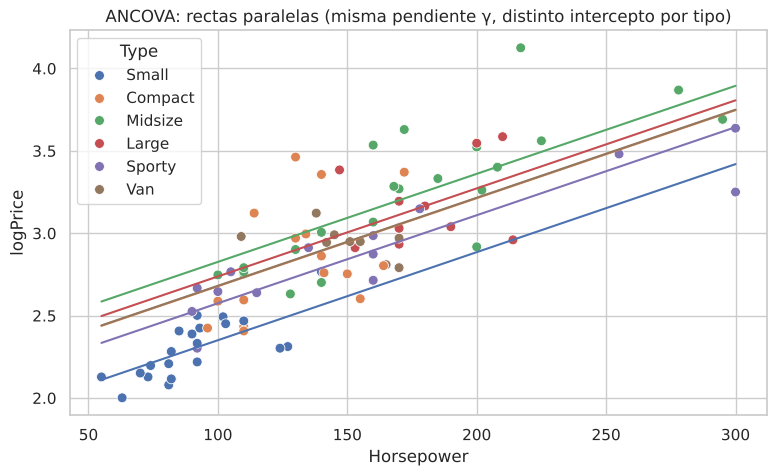

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=cars, x="Horsepower", y="logPrice", hue="Type", ax=ax, s=50)
ancova = smf.ols("logPrice ~ C(Type) + Horsepower", data=cars).fit()
hp = np.linspace(cars.Horsepower.min(), cars.Horsepower.max(), 50)
for i, t in enumerate(orden_tipos):
    ax.plot(hp, ancova.predict(pd.DataFrame({"Type": t, "Horsepower": hp})), color=f"C{i}")
ax.set_title("ANCOVA: rectas paralelas (misma pendiente γ, distinto intercepto por tipo)")
plt.show()

In [34]:
print("1) Supuesto de pendientes homogéneas (¿la interacción Tipo × Horsepower es significativa?)")
print(sm.stats.anova_lm(smf.ols("logPrice ~ C(Type) * Horsepower", data=cars).fit(), typ=2).round(4))

print("\n2) ANCOVA (Tipo II)")
print(sm.stats.anova_lm(ancova, typ=2).round(4))

eta_sin = sm.stats.anova_lm(m_ref).sum_sq.iloc[0] / sm.stats.anova_lm(m_ref).sum_sq.sum()
an = sm.stats.anova_lm(ancova, typ=2)
eta_parcial = an.sum_sq.iloc[0] / (an.sum_sq.iloc[0] + an.sum_sq.iloc[-1])
print(f"\nη² del Tipo SIN ajustar por potencia: {eta_sin:.3f}   |   η² parcial del Tipo AJUSTANDO por potencia: {eta_parcial:.3f}")

1) Supuesto de pendientes homogéneas (¿la interacción Tipo × Horsepower es significativa?)
                    sum_sq    df        F  PR(>F)
C(Type)             1.8820   5.0   7.9583  0.0000
Horsepower          4.4056   1.0  93.1469  0.0000
C(Type):Horsepower  0.3719   5.0   1.5725  0.1772
Residual            3.8311  81.0      NaN     NaN

2) ANCOVA (Tipo II)
            sum_sq    df        F  PR(>F)
C(Type)     1.8820   5.0   7.7019     0.0
Horsepower  4.4056   1.0  90.1464     0.0
Residual    4.2029  86.0      NaN     NaN

η² del Tipo SIN ajustar por potencia: 0.547   |   η² parcial del Tipo AJUSTANDO por potencia: 0.309


**Lectura:**
1. La interacción no es significativa → el supuesto de pendientes homogéneas es razonable.
2. La potencia (`Horsepower`) explica una parte grande del precio. **Después de ajustar** por ella, el tipo de vehículo **sigue** siendo significativo, pero su efecto es **menor**: parte de lo que atribuíamos al "tipo" era en realidad potencia del motor.

> 🔗 El ANCOVA es una regresión con un predictor categórico y uno continuo: el puente natural entre ANOVA y regresión múltiple.

## 5.5 Efectos aleatorios (introducción)

Si los niveles del factor son una **muestra** de una población de niveles (5 lotes de materia prima elegidos al azar entre muchos posibles), no interesa *cada* lote sino **cuánta variabilidad** introducen los lotes:

$$y_{ij}=\mu+a_i+\varepsilon_{ij},\qquad a_i\sim N(0,\sigma_a^2),\ \ \varepsilon_{ij}\sim N(0,\sigma^2)$$

La pregunta cambia de "¿difieren estas medias?" a "¿es $\sigma_a^2>0$?". La **correlación intraclase** $ICC=\sigma_a^2/(\sigma_a^2+\sigma^2)$ mide qué proporción de la variabilidad se debe a los lotes.

In [35]:
rng4 = np.random.default_rng(4)
sigma_a, sigma_e = 2.0, 1.5                                    # verdad: ICC = 4 / (4 + 2.25) = 0.64
lotes = pd.DataFrame([{"Lote": f"L{i}", "Pureza": 95 + a + rng4.normal(0, sigma_e)}
                      for i, a in enumerate(rng4.normal(0, sigma_a, 15)) for _ in range(5)])   # 15 lotes × 5 mediciones
mixto = smf.mixedlm("Pureza ~ 1", data=lotes, groups="Lote").fit(reml=True)
var_a, var_e = float(mixto.cov_re.iloc[0, 0]), mixto.scale
print(mixto.summary())
print(f"σ²_lote estimada = {var_a:.2f} (verdadera {sigma_a**2})   σ²_error = {var_e:.2f} (verdadera {sigma_e**2})")
print(f"ICC = {var_a / (var_a + var_e):.2f}  (verdadera {sigma_a**2 / (sigma_a**2 + sigma_e**2):.2f})")

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: Pureza   
No. Observations: 75      Method:             REML     
No. Groups:       15      Scale:              2.6792   
Min. group size:  5       Log-Likelihood:     -158.2442
Max. group size:  5       Converged:          Yes      
Mean group size:  5.0                                  
-------------------------------------------------------
            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept   94.767    0.537 176.471 0.000 93.715 95.820
Lote Var     3.790    1.109                            

σ²_lote estimada = 3.79 (verdadera 4.0)   σ²_error = 2.68 (verdadera 2.25)
ICC = 0.59  (verdadera 0.64)


> ⚠️ **Precisión de los componentes de varianza.** $\sigma_a^2$ se estima a partir de **cuántos lotes** hay (aquí 15), no de cuántas mediciones totales. Con pocos niveles, la estimación es muy imprecisa: ✏️ cambie la semilla `default_rng(4)` por otros valores y verá que $\hat\sigma_a^2$ oscila bastante alrededor del valor verdadero. Otra vez la estructura manda: para generalizar a "todos los lotes posibles" se necesitan muchos lotes.

## 5.6 El mapa completo: todo es un modelo lineal

```
                         MODELO LINEAL GENERAL   y = Xβ + ε
                                     │
      ┌──────────────┬───────────────┼────────────────┬─────────────────┐
  Regresión       ANOVA           ANCOVA        Modelos mixtos     Extensiones
  (X continuas)  (X categóricas)  (ambas)       (efectos aleatorios)  ├ MANOVA (varias respuestas)
                  ├ 1 factor                                          ├ Medidas repetidas
                  ├ 2+ factores                                       └ Modelos lineales generalizados
                  └ bloques                                              (respuestas binarias, conteos)
```

Todos comparten la misma lógica: **descomponer la variabilidad**, comparar **modelos anidados** con pruebas $F$ y **verificar** que la estructura supuesta sea compatible con los datos.

> 🔗 **Puente con la selección de variables:** la prueba $F$ parcial que usan *forward*, *backward* y *stepwise* para decidir si una variable entra es **la misma** prueba $F$ del ANOVA: compara la variabilidad **adicional** que explica un término contra la variabilidad residual.

---
# Síntesis

| Unidad | Idea central |
|---|---|
| 1. Fundamentos | Comparamos medias analizando si la variabilidad **entre** grupos supera a la variabilidad **dentro**; una sola prueba evita inflar el error tipo I. |
| 2. Estructura | $y_{ij}=\mu+\tau_i+\varepsilon_{ij}$ con $\varepsilon\sim N(0,\sigma^2)$ iid. Los $\tau_i$ requieren una restricción; medias y contrastes son **estimables**. |
| 3. Análisis de varianza | $SC_T=SC_{Tr}+SC_E$; $F=CM_{Tr}/CM_E$; $\eta^2$ mide el tamaño del efecto. |
| 4. Pruebas | $F$ es válida **sólo** bajo la estructura; verificar supuestos; Welch / transformación / Kruskal-Wallis; Tukey y contrastes para saber **qué** difiere. |
| 5. Extensiones | Dos factores (interacción), bloques, ANCOVA, efectos aleatorios: más estructura para representar mejor la realidad. |

### Sobre la competencia: generalizar con la rigidez del modelo en mente

1. **Toda conclusión es condicional al modelo.** "El tipo de auto afecta el precio" significa en realidad: *si los errores son independientes, normales y con varianza común, entonces…*
2. **La simulación nos mostró el costo** de ignorar la estructura: un $p$-valor que promete 5 % puede equivocarse mucho más.
3. **Flexibilizar no es hacer trampa**: transformar, usar Welch o un modelo con más términos es ajustar la estructura a la realidad.
4. **El diseño define el alcance:** con asignación aleatoria → causalidad; con datos observacionales → asociación; con celdas vacías → silencio.

---
# 🧪 Ejercicios propuestos

1. **Un factor.** Con `Cars93`, analice si `MPG_city` difiere según `DriveTrain`. Construya la tabla ANOVA a mano y verifíquela con `statsmodels`. ¿Se cumplen los supuestos? Aplique Tukey.
2. **Rigidez.** Repita la simulación de la Unidad 4.3 con distribuciones **exponenciales** en lugar de normales (`rng.exponential`) y $n=5$ por grupo. ¿Se mantiene el 5 %? ¿Y con $n=30$?
3. **Dos factores.** Cambie las medias verdaderas del experimento industrial para que **no** haya interacción (líneas paralelas) y verifique que el ANOVA lo detecta.
4. **Bloques.** En el ejemplo de métodos de ensamble, aumente la variabilidad entre operarios de 4 a 8. ¿Qué pasa con el $p$-valor del método **sin** bloquear? ¿Y con bloque?
5. **ANCOVA.** Repita el ANCOVA usando `Weight` en lugar de `Horsepower`. ¿Cambia la conclusión sobre el tipo de vehículo?

# Glosario
- **Factor / niveles:** variable categórica que define grupos / sus categorías.
- **$SC_{Tr}$, $SC_E$, $SC_T$:** sumas de cuadrados entre, dentro y total.
- **Cuadrado medio:** suma de cuadrados dividida por sus grados de libertad.
- **Función estimable:** combinación de parámetros cuyo valor no depende de la restricción de identificación (medias, contrastes).
- **Error tipo I por familia:** probabilidad de al menos un falso positivo en un conjunto de pruebas.
- **Interacción:** el efecto de un factor depende del nivel de otro.
- **Bloque:** grupo de unidades homogéneas que recibe todos los tratamientos.
- **Covariable:** variable continua que se ajusta para comparar grupos en igualdad de condiciones.
- **Prueba liberal / conservadora:** rechaza $H_0$ verdadera más / menos veces que el $\alpha$ nominal.

# Referencias
- Montgomery, D. C. (2017). *Design and Analysis of Experiments* (9.ª ed.), caps. 3–5. Wiley.
- Kutner, M., Nachtsheim, C., Neter, J. y Li, W. (2005). *Applied Linear Statistical Models* (5.ª ed.), partes III–IV. McGraw-Hill.
- Searle, S. R. y Gruber, M. (2016). *Linear Models* (2.ª ed.), cap. 5 (funciones estimables). Wiley.
- Welch, B. L. (1951). On the comparison of several mean values: an alternative approach. *Biometrika*, 38, 330–336.
- Lock, R. H. (1993). 1993 New Car Data. *Journal of Statistics Education*, 1(1).